# Traffic Analysis

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [8]:
df = pd.read_csv("/home/jawad/my_jupyter_env/Data_Science_Projects/Urban-Road-Safety-Near-Miss-Analysis/urban_near_miss_dataset_12000.csv")

In [9]:
df.head()

,Record_ID,City,Day_of_Week,Hour,Weather,Traffic_Level,Vehicle_Type,Road_Type,Speed_Limit_kmh,Average_Speed_kmh,Pedestrian_Count,Visibility_Percent,Near_Miss_Score,Incident
0,1,Peshawar,Thursday,6,Cloudy,Medium,Motorcycle,Main Road,60,51.7,11,82.3,40.2,0
1,2,Karachi,Friday,19,Clear,Medium,Bus,Residential,50,51.8,10,91.1,31.6,0
2,3,Rawalpindi,Friday,14,Clear,Medium,Rickshaw,Residential,50,74.7,11,82.2,44.8,0
3,4,Peshawar,Sunday,10,Rain,High,Car,Main Road,60,39.4,7,74.0,35.6,0
4,5,Rawalpindi,Saturday,7,Rain,Severe,Rickshaw,Highway,100,62.5,8,97.3,57.1,1


In [12]:


# how many possible categories ?
traffic_order =  ['Low', 'Medium', 'High', 'Severe']
df["Traffic_Level"] = pd.Categorical(df['Traffic_Level'],categories= traffic_order,ordered= True)

# how many belong to each traffic level ?
count = df["Traffic_Level"].value_counts().reindex(traffic_order)
print("\n",count)
print("__"*35)


# which traffic level has the most incident ?
traffic_level = df.groupby("Traffic_Level")["Incident"].sum()
most_incidentt = traffic_level.idxmax()
print("\ntraffic level most incident : ",most_incidentt)


# which traffic level has the highest average near miss score ?
avg_near_miss_score = df.groupby("Traffic_Level")["Near_Miss_Score"].mean()
avg_high_miss_Score = avg_near_miss_score.idxmax()
print("Traffic Level has the highest average near miss score : ", avg_high_miss_Score)





 Traffic_Level
Low       2985
Medium    4250
High      3285
Severe    1480
Name: count, dtype: int64
______________________________________________________________________

traffic level most incident :  High
Traffic Level has the highest average near miss score :  Severe


# Traffic level Vs Average Near Miss Score 

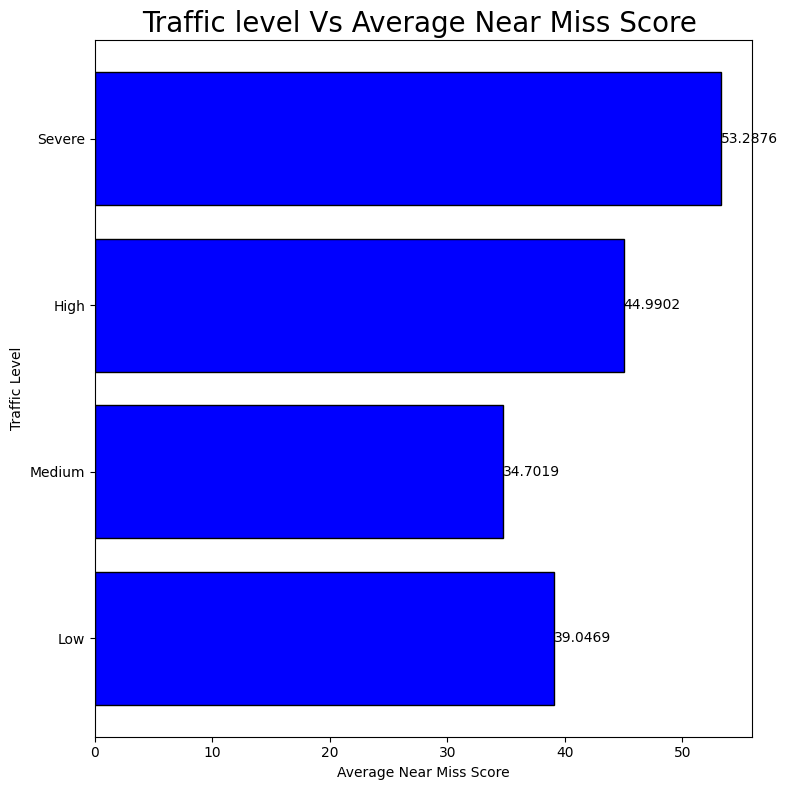

In [11]:
avg_miss_score = df.groupby("Traffic_Level")["Near_Miss_Score"].mean()
plt.figure(figsize=(8,8))
bar = plt.barh(avg_miss_score.index,avg_miss_score.values,color="blue",edgecolor="Black")
plt.bar_label(bar)
plt.title("Traffic level Vs Average Near Miss Score ",fontsize = 20)
plt.xlabel("Average Near Miss Score")
plt.ylabel("Traffic Level")
plt.tight_layout()
plt.savefig("Traffic_level_Vs_Average_Near_Miss_Score.png",dpi =300,bbox_inches = "tight")

plt.show()